<a href="https://colab.research.google.com/github/lorenzo-fattori/dtm-dcai/blob/main/slides/lab-05-privacy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/w4bo/AA2627-unibo-dcai/blob/main/slides/lab-05-privacy.ipynb" target="_parent"><img src="https://github.com/w4bo/AA2627-unibo-dcai/blob/main/slides/img/colab-badge.svg?raw=1" alt="Open In Colab"/></a>


---
title: "Privacy-Aware AI"
bibliography:
  - refs/refs.bib
---


# Session plan: theory and coding

| Activity |
| --- |
| Theory 1: Record linkage, k-anonymity, generalization, suppression, and Adult audits |
| [Coding 1 (~15 min): Exercises 1 and 2](#coding-exercises-1) |
| Theory 2: l-diversity, t-closeness, decision-tree utility, and retained-group coverage |
| [Coding 2 (~15 min): Exercises 3 and 4](#coding-exercises-2) |
| Theory 3: Membership inference, differential privacy, forest budgets, and privacy/utility comparisons |
| [Coding 3 (~15 min): Exercises 5 and 6](#coding-exercises-3) |

# Why database privacy is hard

<a id="theory-block-1"></a>

Census-income tables contain demographic combinations that can point back to individuals [@sweeney2002kanonymity; @jin2023survey].

However, the privacy problem is not only "who is this?"

| Disclosure type | What goes wrong | Example question |
|---|---|---|
| Identity disclosure | A person is linked to a record | Which row belongs to this person? |
| Attribute disclosure | A sensitive fact is inferred | Does this person earn more than $50K? |

- Identity disclosure often leads to attribute disclosure
- Attribute disclosure can happen even when identity remains uncertain.
- Releasing data is useful, but replacing names with numbers rarely makes people anonymous [@fung2010privacy].


# Identifiers come in layers

| Type | Examples | Privacy role |
| --- | --- | --- |
| Direct identifiers | Name, phone, address, identification number | Identify directly |
| Quasi-identifiers | Age, education, marital status, race, sex | Can identify through combinations or linkage |
| Sensitive attributes | Income, racial or ethnic origin | Facts whose disclosure can harm someone |

- **[GDPR (EU): Articles 4 and 9; Recital 26](https://eur-lex.europa.eu/legal-content/EN/TXT/?uri=CELEX%3A32016R0679).** Personal data include direct and indirect identification; pseudonymized data remain personal when re-identification is possible. Health and racial/ethnic origin are *special categories*; income alone is not an Article 9 category.
- **[HIPAA (US health information)](https://www.hhs.gov/hipaa/for-professionals/special-topics/de-identification/index.html).** De-identification uses Expert Determination or Safe Harbor, which requires removing specified identifiers and meeting its additional conditions.
- **[CCPA, amended by CPRA (California)](https://www.oag.ca.gov/privacy/ccpa).** Personal information includes data reasonably linkable to a consumer or household; *sensitive personal information* is a defined subset.


# What can an attacker know?

An attacker rarely starts from zero.

| Prior knowledge | How it helps |
|---|---|
| Public records | Links age, education, marital status, and demographic facts |
| Social media | Reveals education, occupation, relationships, and family details |
| Domain knowledge | Makes some sensitive values more or less plausible |
| Other releases | Enables comparison across time or across datasets |

Privacy models are assumptions about which attacks we are trying to limit.


# Attack: record linkage


| Outside knowledge | Released Adult record |
| --- | --- |
| Age 31, education level 10, Married-civ-spouse, White, Male | The same QIs together with income >50K |

- An attacker knows a person's age, education, marital status, race and sex from outside sources.
- A released income table contains those same columns [@sweeney2002kanonymity; @fung2010privacy].
- If that combination identifies only one record in the release, knowing the person's QIs links them to the income label.


# Group records that share the same quasi-identifiers

Choose the **quasi-identifiers (QIs)**: the columns an attacker might know about a person.

- A **QI group** is a group of records with identical values in all displayed QI columns.
- The group's size is the number of matching records.

> If five records share the same displayed age, education, marital status, race and sex, they form one group of size 5. Their income labels may differ: income is the sensitive attribute, not part of the grouping key.


# Definition: $k$-anonymity

**$k$ is the chosen minimum number of matching records in each group**; for example, choose $k = 3$.

A released table is **$k$-anonymous with respect to chosen quasi-identifiers** if **every QI group contains at least $k$ records** [@sweeney2002kanonymity].

$$\forall E,\quad |E|\geq k.$$

The table's achieved $k$ is its **smallest** group size, not its average group size.


- **What is checked?** The number of records sharing each displayed QI combination.
- **Example:** group sizes 3, 5 and 8 satisfy $k = 3$. Sizes 2, 5 and 8 do not.
    - $k = 1$ requirement provides no meaningful anonymity guarantee.


# Adult dataset



In [1]:
#| echo: false
#| output: false
import importlib.util
import subprocess
import sys
from importlib.metadata import version

packages = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
            "sklearn": "scikit-learn>=1.4,<1.8", "diffprivlib": "diffprivlib==0.6.6"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if importlib.util.find_spec("sklearn") is not None:
    if not (1, 4) <= tuple(map(int, version("scikit-learn").split(".")[:2])) < (1, 8):
        missing.append("scikit-learn>=1.4,<1.8")
if importlib.util.find_spec("diffprivlib") is not None and version("diffprivlib") != "0.6.6":
    missing.append("diffprivlib==0.6.6")
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
# Restart the kernel if an already-imported sklearn version was changed.


In [2]:
#| echo: false
from pathlib import Path
from urllib.request import urlopen
import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
from diffprivlib.models import RandomForestClassifier as DPRandomForestClassifier
from diffprivlib.accountant import BudgetAccountant

RANDOM_STATE = 42
TARGET_K = 3
QI = ["age", "education_num", "marital_status", "race", "sex"]
SENSITIVE = "income"
GEN_QI = ["age_band", "education_band", "marital_group", "race", "sex"]
plt.style.use("seaborn-v0_8-whitegrid")

cache = Path(".cache/datasets/adult-privacy.csv")
if not cache.exists():
    payload = urlopen("https://archive.ics.uci.edu/static/public/2/data.csv", timeout=60).read()
    # Validate the download before caching it; a failed download is not replaced with fake data.
    pd.read_csv(io.BytesIO(payload), nrows=2)
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_bytes(payload)
adult_original = pd.read_csv(cache, na_values="?", skipinitialspace=True)
adult_original.columns = adult_original.columns.str.lower().str.replace("-", "_", regex=False)
adult_original.head()


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


# Adult: choose the privacy roles before computing $k$

| Role | Columns in this lesson
| --- | --- |
| Quasi-identifiers | ??? |
| Sensitive target | ??? |

In [3]:
list(adult_original.columns)

['age',
 'workclass',
 'fnlwgt',
 'education',
 'education_num',
 'marital_status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'capital_gain',
 'capital_loss',
 'hours_per_week',
 'native_country',
 'income']

# Adult: choose the privacy roles before computing $k$

| Role | Columns in this lesson | Why? |
| --- | --- | --- |
| Quasi-identifiers / model inputs | age, education, marital status, race, sex | A person may be linkable through a combination of demographic values |
| Sensitive target | income above or below $50K | The prediction task and the fact an attacker may infer |

- **A $k$-anonymity claim is relative to the declared QIs.**
- Income is not included in the grouping key.


In [4]:
#| echo: false
adult_original.columns = adult_original.columns.str.lower().str.replace("-", "_", regex=False)
df = adult_original[QI + [SENSITIVE]].copy()
for col in ["marital_status", "race", "sex", SENSITIVE]:
    df[col] = df[col].str.strip()
df[SENSITIVE] = df[SENSITIVE].str.replace(".", "", regex=False)
df = df.dropna(subset=QI+[SENSITIVE]).reset_index(drop=True)
display(df.head())
display(df[SENSITIVE].value_counts(normalize=True).rename("income_share").round(3))


,age,education_num,marital_status,race,sex,income
0,39,13,Never-married,White,Male,<=50K
1,50,13,Married-civ-spouse,White,Male,<=50K
2,38,9,Divorced,White,Male,<=50K
3,53,7,Married-civ-spouse,Black,Male,<=50K
4,28,13,Married-civ-spouse,Black,Female,<=50K


,income_share
income,
<=50K,0.761
>50K,0.239


In [5]:
#| echo: false
# Select the nine actual downloaded records printed in the table below.
excerpt = df.loc[[33, 57, 38, 66, 103, 2603, 92, 326, 344], QI + [SENSITIVE]].copy()


# Adult excerpt: nine real records before generalization

| Age | Education level | Marital status | Race | Sex | Income |
| --- | --- | --- | --- | --- | --- |
| 30 | 10 | Married-civ-spouse | White | Male | <=50K |
| 35 | 11 | Married-civ-spouse | White | Male | <=50K |
| 31 | 10 | Married-civ-spouse | White | Male | >50K |
| 28 | 10 | Divorced | White | Female | <=50K |
| 20 | 10 | Never-married | White | Female | <=50K |
| 24 | 9 | Divorced | White | Female | >50K |
| 28 | 10 | Divorced | Black | Female | <=50K |
| 23 | 11 | Never-married | Black | Female | <=50K |
| 22 | 10 | Never-married | Black | Female | <=50K |

- Every displayed five-QI combination is unique within the excerpt: its minimum group size is 1.
- Names are absent, but that alone does not provide anonymity.


In [6]:
#| echo: true
#| output: false
# Income is sensitive, so group only by the five quasi-identifiers.
group_counts = excerpt.groupby(QI, dropna=False).size().rename("rows")
print("Minimum group size (achieved k):", group_counts.min())
group_counts


Minimum group size (achieved k): 1


age  education_num  marital_status      race   sex   
20   10             Never-married       White  Female    1
22   10             Never-married       Black  Female    1
23   11             Never-married       Black  Female    1
24   9              Divorced            White  Female    1
28   10             Divorced            Black  Female    1
                                        White  Female    1
30   10             Married-civ-spouse  White  Male      1
31   10             Married-civ-spouse  White  Male      1
35   11             Married-civ-spouse  White  Male      1
Name: rows, dtype: int64

# Generalize the same nine Adult records

Replace

1. exact ages with 10-year bands,
2. education with four-level bands and
3. marital status with married / not married.

Keep race, sex and income.

| Age band | Education band | Marital group | Race | Sex | Income |
| --- | --- | --- | --- | --- | --- |
| 30–39 | 9–12 | Married | White | Male | <=50K |
| 30–39 | 9–12 | Married | White | Male | <=50K |
| 30–39 | 9–12 | Married | White | Male | >50K |
| 20–29 | 9–12 | Not married | White | Female | <=50K |
| 20–29 | 9–12 | Not married | White | Female | <=50K |
| 20–29 | 9–12 | Not married | White | Female | >50K |
| 20–29 | 9–12 | Not married | Black | Female | <=50K |
| 20–29 | 9–12 | Not married | Black | Female | <=50K |
| 20–29 | 9–12 | Not married | Black | Female | <=50K |

Compare all five displayed QIs when grouping

- Income is the sensitive value and is not a grouping key.


# Adult example: check $k = 3$ after generalization

The same nine records now form three QI groups.

| Group | Age / education / marital group / race / sex | Size |
| --- | --- | --- | ---: |
| A | 30–39 / 9–12 / Married / White / Male | 3 |
| B | 20–29 / 9–12 / Not married / White / Female | 3 |
| C | 20–29 / 9–12 / Not married / Black / Female | 3 |

The smallest group has size 3, so this generalized excerpt is **3-anonymous** for the five QIs.


# Adult example: leaving one record precise breaks the guarantee

Suppose the third record in group A keeps its original QIs while the first two are generalized:

| Age | Education | Marital status/group | Race | Sex | Income |
| --- | --- | --- | --- | --- | --- |
| 30–39 | 9–12 | Married | White | Male | <=50K |
| 30–39 | 9–12 | Married | White | Male | <=50K |
| 31 | 10 | Married-civ-spouse | White | Male | >50K |

The excerpt no longer meets $k = 3$, even if all other records remain properly generalized.


# Suppression is the other lever

When one record prevents a table from satisfying $k$, we can suppress fields or rows.

| Technique | Effect | Cost |
|---|---|---|
| Generalization | Keeps records, coarsens values | Less precision |
| Suppression | Removes risky values or rows | Less coverage |

*Privacy is a tradeoff against data utility.*


# Privacy and utility pull against each other

Privacy transformations reduce what an attacker can learn, but they also reduce what an analyst can use [@fung2010privacy; @jin2023survey].

- The practical question is not "maximum privacy"; it is the best point on the privacy-utility curve [@friedman2010datamining; @jin2023survey].

| Privacy action | Utility consequence |
|---|---|
| Coarser values | Less precise models and statistics |
| More suppression | Smaller or less representative data |
| More noise | Less stable query answers |
| Smaller privacy budget | Fewer useful interactions with the data |


# Adult: audit groups, then build a release

Apply the following generalization and suppression policy.

- Age: 10-year bands; education: four-level bands.
- Marital status: married / not married; race and sex retained.
- Suppress entire QI groups containing fewer than 3 records.

Check the minimum group size after suppression. Generalization alone may leave groups that are too small.


In [7]:
#| echo: false
def group_sizes(table, qi):
    return table.groupby(qi, observed=True, dropna=False).size()

def audit_k(table, qi, target=TARGET_K):
    if table.empty:
        raise ValueError("Empty release: k-anonymity is not a useful claim.")
    sizes = group_sizes(table, qi)
    return pd.Series({"records": len(table), "groups": len(sizes), "k_min": int(sizes.min()),
        "singleton_share": sizes[sizes == 1].sum()/len(table),
        "share_rows_below_k": sizes[sizes < target].sum()/len(table),
        "meets_target": bool(sizes.min() >= target)})

def generalize(table):
    out = table.copy()
    out["age_band"] = (out["age"] // 10) * 10
    out["education_band"] = ((out["education_num"] - 1) // 4) * 4 + 1
    out["marital_group"] = np.where(
        out["marital_status"].str.startswith("Married"), "Married", "Not married")
    return out[GEN_QI + [SENSITIVE]]


def suppress(table, qi, k=TARGET_K):
    sizes = table.groupby(qi, observed=True, dropna=False)[SENSITIVE].transform("size")
    return table.loc[sizes >= k].copy()

raw_audit = audit_k(df, QI)
generalized = generalize(df)
release = suppress(generalized, GEN_QI)
assert audit_k(release, GEN_QI)["meets_target"]
display(pd.DataFrame({"raw": raw_audit, "generalized": audit_k(generalized, GEN_QI),
                      "3-anonymous release": audit_k(release, GEN_QI)}).T)
print(f"Retained share: {len(release)/len(df):.2%}")


,records,groups,k_min,singleton_share,share_rows_below_k,meets_target
raw,48842,7976,1,0.080832,0.13169,False
generalized,48842,478,1,0.001699,0.003665,False
3-anonymous release,48663,347,3,0.0,0.0,True


Retained share: 99.63%


# How many rows share each QI combination?

Each row contributes to the bar for its group's size. A bar at 3 counts records that belong to groups of exactly 3.

- The bar at 20 combines group sizes of 20 or more.
- After suppression, no retained row belongs to a group smaller than 3.


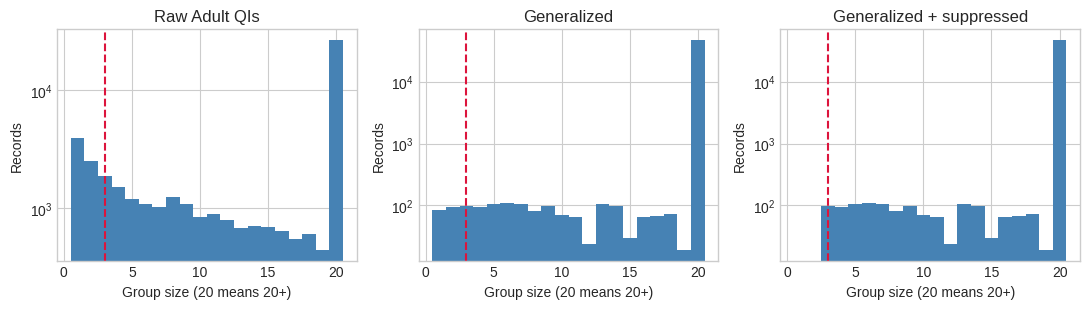

In [8]:
#| echo: false
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (title, table, qi) in zip(axes, [("Raw Adult QIs", df, QI),
        ("Generalized", generalized, GEN_QI), ("Generalized + suppressed", release, GEN_QI)]):
    row_sizes = table.groupby(qi, observed=True, dropna=False)[SENSITIVE].transform("size")
    ax.hist(row_sizes.clip(upper=20), bins=np.arange(0.5,21.5), color="steelblue")
    ax.axvline(3, color="crimson", linestyle="--")
    ax.set(title=title, xlabel="Group size (20 means 20+)", ylabel="Records")
    ax.set_yscale("log")
plt.tight_layout()
plt.show()


{{< include _coding_break1.qmd >}}


# Can a person's income still be inferred from the groups?


# $k$-anonymity known issues

<a id="theory-block-2"></a>

**Homogeneity attack**

- Everyone in a QI group has the same sensitive value.
- Knowing the group is enough to infer the value.

**Background knowledge can still reveal income**

- Group A in our Adult excerpt has three matching QI records and income labels **[<=50K, <=50K, >50K]**.
- Suppose an attacker knows that a target person is one of the three released members.
    - If outside information also reveals that the other two members earn <=50K, the target's income must be >50K.


# Definition: $l$-diversity (distinct version)

A released table satisfies **distinct $l$-diversity** if **every QI group contains at least $l$ distinct values of the sensitive attribute** [@machanavajjhala2006ldiversity].

$$\forall E,\quad |\{S(r):r\in E\}|\geq l,$$

where $S(r)$ is the sensitive value in record $r$. Here $S$ is the income label.

- **Example:** a three-record group with incomes [<=50K, <=50K, >50K] satisfies $k = 3$ and distinct $l = 2$.
- A three-record group with [<=50K, <=50K, <=50K] satisfies $k = 3$ but fails distinct $l = 2$.

Other $l$-diversity variants impose frequency requirements.


# Adult example: $k$-anonymity does not imply $l$-diversity

Count sensitive income values inside the same three groups.

| Group | Records <=50K | Records >50K | $k = 3$? | Distinct $l = 2$? |
| --- | ---: | ---: | --- | --- |
| A: White, Male, 30–39, married | 2 | 1 | yes | yes |
| B: White, Female, 20–29, not married | 2 | 1 | yes | yes |
| C: Black, Female, 20–29, not married | 3 | 0 | yes | no |

Groups A and B each contain **two <=50K records and one >50K record**. Both are distinct-2-diverse.

- Their high-income share is 1/3, whereas the whole excerpt's share is 2/9.
- Distinct diversity requires both labels to be present. With this binary target (<=50K vs >50K), distinct $l$ can never exceed 2.

If a person is known to be a released member of group C, their income class is revealed even though their individual row is hidden.


# $l$-diversity known issues

Diversity checks the presence of values, not how close their proportions are to the whole release.

Learning a person's group changes the income distribution an attacker associates with that person.

- In the nine-record excerpt, **2 of 9** people have income >50K: the whole-release rate is **22.2%**.
- In group A, **1 of 3** has income >50K: the group rate is **33.3%**.


# Definition: $t$-closeness

A released table satisfies **$t$-closeness** if, in **every QI group**, the sensitive-value distribution is within distance $t$ of the distribution in the whole released table [@li2007tcloseness].

$$\forall E,\quad EMD(P_E,Q)\leq t.$$

$P_E$ is the group distribution; $Q$ is the whole-table distribution.

- **Earth Mover Distance (EMD)**: the minimum work needed to move probability mass between income categories.
- If $Q$ is public, the privacy question becomes: how much extra does `P` reveal?

```{mermaid}
%%| echo: false
flowchart LR
  A[Prior belief] --> B[Learn global distribution Q]
  B --> C[Learn QI-group distribution P]
  C --> D[Posterior belief]
  B -. t-closeness limits this change .-> C
```

> With two categories and unit ground distance: $EMD(P_E,Q)=|P_E(>50K)-Q(>50K)|.$
>
> - In the nine-record excerpt, the whole-release rate is 2/9.
> - In group A, the rate is 1/3 and the distance is 1/9 ≈ 0.111.
> - In group C, the rate is 0 and the distance is 2/9 ≈ 0.222.
> - At $t = 0.15$, A passes and C fails.


# Earth Mover Distance: move income probability mass

There are two categories: <=50K and >50K.

- Staying in the same category (distance 0) and moving to the other category (distance 1).

- For these two categories and unit ground distance, EMD is the **probability mass that must be moved**: the absolute difference in high-income shares.
- **Work = probability mass moved × distance between the categories.**

Use group A and the whole nine-record release:

| Distribution | <=50K | >50K |
| --- | ---: | ---: |
| Whole excerpt Q | **7/9** | 2/9 |
| Group A | 2/3 = 6/9 | **1/3 = 3/9** |

Move **1/9** of probability mass from >50K to <=50K. With category distance 1:

$$EMD(P_A,Q)=\tfrac19\times1=\tfrac19\approx0.111.$$


# Compare all three groups at $t = 0.15$

The excerpt is 3-anonymous, but it does **not** satisfy distinct 2-diversity or $t = 0.15$ closeness, because group C fails both checks.

| Group | High-income share | EMD from Q(>50K) = 2/9 | Passes $t = 0.15$? |
| --- | ---: | ---: | --- |
| A | 1/3 | 1/9 ≈ 0.111 | yes |
| B | 1/3 | 1/9 ≈ 0.111 | yes |
| C | 0 | 2/9 ≈ 0.222 | no |


Stronger closeness can remove useful demographic detail

- If all nine records are merged into one generalized QI group, its income distribution is exactly the whole-release distribution: EMD 0.
- The released QIs would need to hide the distinctions separating A, B and C, including age band, marital group, race and sex.
- Identity groups become larger and income distributions closer, while those demographic distinctions disappear from the analysis.


# Adult: $k = 3$ can still reveal income

The full-data calculation below uses its own retained-population reference rate, not the excerpt rate 2/9.

- The suppression procedure enforces $k = 3$ only. The diversity and closeness results below are diagnostic checks; violations can remain.


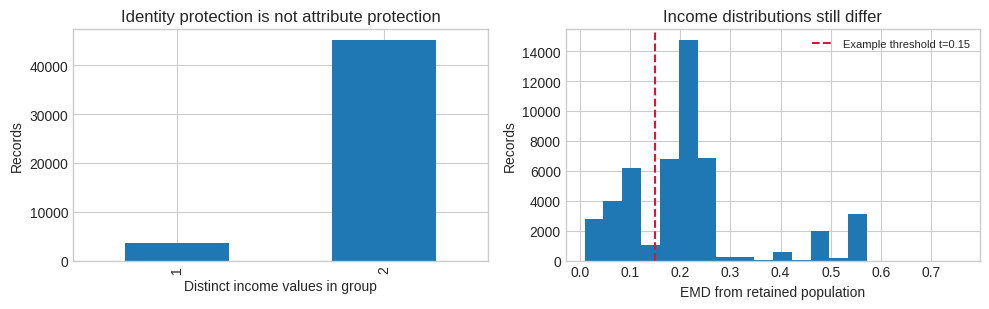

In [9]:
#| echo: false
income_groups = release.assign(high=release.income.eq(">50K").astype(int)).groupby(GEN_QI, observed=True).agg(
    n=("high", "size"), high_share=("high", "mean"), distinct_income=("income", "nunique"))
global_income_rate = release.income.eq(">50K").mean()
def income_emd(group_high_share, population_high_share):
    # Exact EMD for two income categories with unit distance between them.
    return abs(group_high_share - population_high_share)

income_groups["emd_distance"] = income_emd(income_groups.high_share, global_income_rate)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
income_groups.groupby("distinct_income").n.sum().plot.bar(ax=axes[0])
axes[0].set(xlabel="Distinct income values in group", ylabel="Records", title="Identity protection is not attribute protection")
axes[1].hist(income_groups.emd_distance, bins=20, weights=income_groups.n)
axes[1].axvline(0.15, color="crimson", linestyle="--", label="Example threshold t=0.15")
axes[1].set(xlabel="EMD from retained population", ylabel="Records", title="Income distributions still differ")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


# Compare the three privacy definitions

| Criterion | Check in every QI group | Parameter direction | Main limitation |
| --- | --- | --- | --- |
| $k$-anonymity | At least $k$ matching records | Larger $k$ imposes a stricter size requirement | Members may share one sensitive value |
| Distinct $l$-diversity | At least $l$ distinct sensitive values | Larger $l$ requires more variety | Values may be extremely unbalanced |
| $t$-closeness | Sensitive distribution at EMD at most $t$ from the whole table | Smaller $t$ requires greater closeness | Result depends on the distance and reference population |


In [10]:
#| echo: false
train_idx, test_idx = train_test_split(df.index, test_size=0.3, random_state=RANDOM_STATE, stratify=df[SENSITIVE])
train_df, test_df = df.loc[train_idx].copy(), df.loc[test_idx].copy()
gen_train, gen_test = generalize(train_df), generalize(test_df)
anon_train = suppress(gen_train, GEN_QI)
y_train = train_df.income.eq(">50K").astype(int)
y_test = test_df.income.eq(">50K").astype(int)
assert audit_k(anon_train, GEN_QI).meets_target
assert set(train_idx).isdisjoint(test_idx)


# A pipeline with a decision tree

1. Reuse one stratified 70/30 training/test split.
2. Encode categories with fixed, declared domains and scale features to [0, 1].
3. Fit a depth-5 tree with at least 20 training records per leaf.

For the anonymized model, generalize both splits and suppress **training groups only**.


In [11]:
#| echo: false
MARITAL = ["Divorced", "Married-AF-spouse", "Married-civ-spouse", "Married-spouse-absent",
           "Never-married", "Separated", "Widowed"]
RACES = ["Amer-Indian-Eskimo", "Asian-Pac-Islander", "Black", "Other", "White"]
SEXES = ["Female", "Male"]

def fixed_scale(values, lower, upper):
    values = np.asarray(values, dtype=float)
    return np.clip((values-np.asarray(lower))/(np.asarray(upper)-np.asarray(lower)), 0, 1)

def make_preprocessor(generalized=False):
    numeric = ["age_band", "education_band"] if generalized else ["age", "education_num"]
    categorical = ["marital_group", "race", "sex"] if generalized else ["marital_status", "race", "sex"]
    domains = [["Married", "Not married"], RACES, SEXES] if generalized else [MARITAL, RACES, SEXES]
    lower, upper = ([0, 1], [90, 16]) if generalized else ([17, 1], [90, 16])
    num = FunctionTransformer(fixed_scale, kw_args={"lower": lower, "upper": upper}, feature_names_out="one-to-one")
    cat = Pipeline([("codes", OrdinalEncoder(categories=domains)),
                    ("scale", FunctionTransformer(fixed_scale, kw_args={"lower": [0,0,0], "upper": [len(d)-1 for d in domains]}, feature_names_out="one-to-one"))])
    return ColumnTransformer([("numeric", num, numeric), ("categories", cat, categorical)])

def make_tree_pipeline(generalized=False):
    return Pipeline([("prepare", make_preprocessor(generalized)),
        ("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=RANDOM_STATE))])

def evaluate(pipeline, features, name):
    assert features.index.equals(y_test.index), "Evaluation people or their order changed."
    predicted = pipeline.predict(features)
    assert len(predicted) == len(y_test)
    return {"model": name, "accuracy": accuracy_score(y_test, predicted),
            "balanced_accuracy": balanced_accuracy_score(y_test, predicted),
            "f1": f1_score(y_test, predicted, zero_division=0), "test_people": len(predicted)}


In [12]:
#| echo: false
raw_tree = make_tree_pipeline().fit(train_df[QI], y_train)
anon_tree = make_tree_pipeline(True).fit(anon_train[GEN_QI], anon_train.income.eq(">50K").astype(int))
tree_results = pd.DataFrame([
    evaluate(raw_tree, test_df[QI], "Raw decision tree"),
    evaluate(anon_tree, gen_test[GEN_QI], "Anonymized decision tree, k=3"),
])
tree_results["training_rows"] = [len(train_df), len(anon_train)]
tree_results["target_k"] = [np.nan, TARGET_K]
tree_results["achieved_k"] = [audit_k(train_df,QI).k_min, audit_k(anon_train,GEN_QI).k_min]
tree_results["retained_share"] = tree_results.training_rows/len(train_df)
display(tree_results[["model","target_k","achieved_k","retained_share","balanced_accuracy"]].round(3))


,model,target_k,achieved_k,retained_share,balanced_accuracy
0,Raw decision tree,NaN,1,1.000,0.686
1,"Anonymized decision tree, k=3",3.0,3,0.995,0.678


How do the raw and anonymized trees differ in predictive utility and training coverage?


# Which features did the tree actually use?


,feature,split_count,importance
2,categories__marital_status,3,0.557
1,numeric__education_num,8,0.371
0,numeric__age,14,0.064
4,categories__sex,6,0.007
3,categories__race,0,0.000


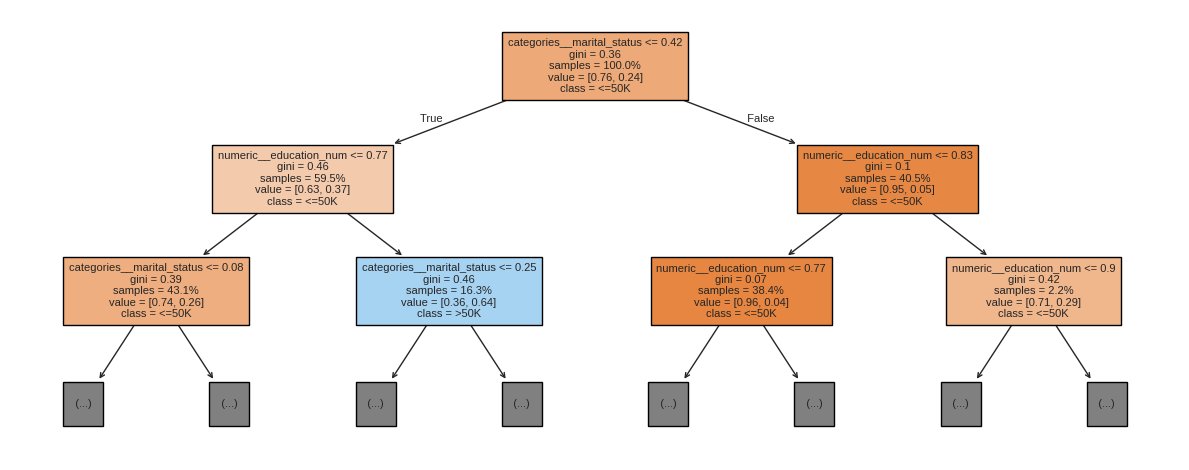

In [13]:
#| echo: false
def tree_feature_report(pipeline):
    names = pipeline.named_steps["prepare"].get_feature_names_out()
    fitted = pipeline.named_steps["model"]
    indices = fitted.tree_.feature
    counts = np.bincount(indices[indices >= 0], minlength=len(names))
    return pd.DataFrame({"feature": names, "split_count": counts,
                         "importance": fitted.feature_importances_}).sort_values("importance", ascending=False)

display(tree_feature_report(raw_tree).round(3))
fig, ax = plt.subplots(figsize=(12, 4.8))
plot_tree(raw_tree.named_steps["model"], max_depth=2,
          feature_names=raw_tree.named_steps["prepare"].get_feature_names_out(),
          class_names=["<=50K", ">50K"], filled=True, proportion=True, precision=2, fontsize=8, ax=ax)
plt.tight_layout()
plt.show()


# One anonymization policy, one comparison

- Age: 10-year bands; education: four-level bands.
- Marital status: married / not married; race and sex retained.
- Suppress training groups smaller than 3.
- Compare the raw and anonymized trees on the same test people.

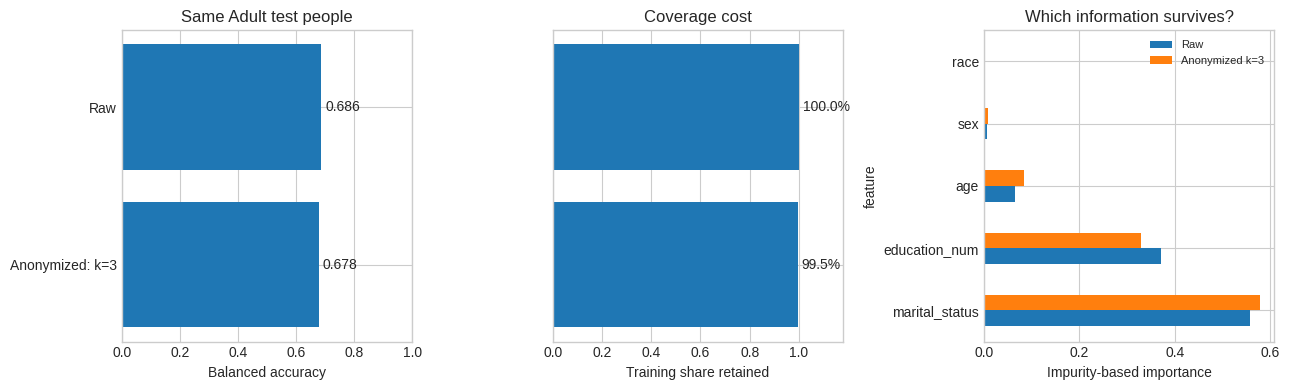

In [14]:
#| echo: false
labels = ["Raw", "Anonymized: k=3"]
fig, axes = plt.subplots(1,3,figsize=(13,4))
bars = axes[0].barh(labels, tree_results.balanced_accuracy)
axes[0].bar_label(bars,fmt="%.3f",padding=3)
axes[0].invert_yaxis()
axes[0].set(xlim=(0,1),xlabel="Balanced accuracy",title="Same Adult test people")
bars = axes[1].barh(labels,tree_results.retained_share)
axes[1].bar_label(bars,labels=[f"{x:.1%}" for x in tree_results.retained_share],padding=3)
axes[1].invert_yaxis()
axes[1].set_yticklabels([])
axes[1].set(xlim=(0,1.18),xlabel="Training share retained",title="Coverage cost")
importance = {}
for name,model in [("Raw",raw_tree),("Anonymized k=3",anon_tree)]:
    report = tree_feature_report(model)
    names = report.feature.str.replace("numeric__","",regex=False).str.replace("categories__","",regex=False)
    names = names.replace({"age_band":"age","education_band":"education_num","marital_group":"marital_status"})
    importance[name] = pd.Series(report.importance.to_numpy(),index=names)
pd.DataFrame(importance).fillna(0).plot.barh(ax=axes[2])
axes[2].set(xlabel="Impurity-based importance",title="Which information survives?")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()


# Suppression can change who is represented

The released training table may exclude rare demographic combinations.

- A small utility change on average can hide a coverage loss for a small group.


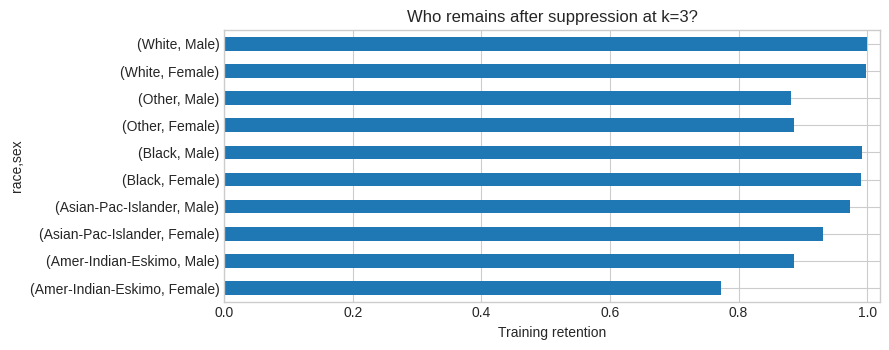

In [15]:
#| echo: false
coverage = train_df.assign(retained=train_df.index.isin(anon_train.index)).groupby(["race","sex"], observed=True).agg(
    training_people=("retained", "size"), retained_share=("retained", "mean"))
fig, ax = plt.subplots(figsize=(9, 3.6))
coverage.retained_share.plot.barh(ax=ax)
ax.set(xlim=(0,1.02), xlabel="Training retention", title="Who remains after suppression at k=3?")
plt.tight_layout()
plt.show()


{{< include _coding_break2.qmd >}}


# Membership inference

Membership inference asks whether a specific person's record was included in model training.

> Was this person's census-income record used to train the released classifier?

Knowing the income class and knowing training membership are different disclosures.


# Table anonymity and model privacy are different guarantees

- $k$-anonymity, $l$-diversity and $t$-closeness impose formal conditions on a **released table** [@jin2023survey].
- Their guarantees depend on the chosen QIs, sensitive attribute and attacker assumptions.
- They do not bound every re-identification or inference risk.


# Definition: differential privacy

Two training datasets D and D′ are **neighbors** if they differ by the addition or removal of one person's record.

- A randomized training algorithm M provides **$\epsilon$-differential privacy** if, for every neighboring pair $D, D′$ and every set $S$ of possible output models [@dwork2006differential]:

$$\Pr[M(D)\in S]\leq e^{\epsilon}\Pr[M(D')\in S].$$

- **$M$:** the randomized training algorithm that takes dataset $D$ and releases a trained model (e.g., a decision tree).
- **Probability:** over the algorithm's choices.
- **Smaller $\epsilon$:** a tighter limit on how much one person's participation can change output probabilities.

For $\epsilon= 0.1$, the probability of any output event can change by at most a factor of $e^{0.1} \approx 1.105$.

- This is a bound on participation's influence, not a probability of identifying someone.


# Differential Privacy Example: Count Queries

The same DP definition applies when $M$ releases a query answer rather than a trained model. Assume **one record per person** and add/remove neighbors.

> How many people have income above 50K?

Adding or removing one person changes the count $q(D)$ by at most **1**. This worst-case change is its sensitivity:

$$\Delta q=\max_{D\sim D'}|q(D)-q(D')|=1.$$

The **Laplace mechanism** releases:

$$M(D)=q(D)+Z,\qquad Z\sim\operatorname{Laplace}(0,b),\qquad b=\frac{\Delta q}{\epsilon}=\frac{1}{\epsilon}.$$

The noise probability density is $f_Z(z)=\frac{1}{2b}\exp\!\left(-\frac{|z|}{b}\right)$ for $z\in\mathbb{R}$.

- Neighboring datasets might have true counts **40 and 41**; both yield overlapping distributions of noisy answers.
- Smaller $\epsilon$ gives stronger privacy and more noise for this query.

:::{.notes}
Laplace(0, b) denotes zero-centered Laplace noise with scale b, not variance b. Its expected absolute magnitude is b. The general scalar Laplace mechanism uses scale Delta q / $\epsilon$ and provides pure $\epsilon$-DP.

Overlap alone does not establish DP: the probability of every output event must satisfy the definition's multiplicative bound. The raw count plus Laplace noise has that guarantee. Rounding or clipping the noisy answer to be nonnegative is post-processing and preserves the guarantee.

The count query is a predicate count, not the dataset size; only people satisfying the predicate contribute 1. A bound of one contribution per person is essential for person-level sensitivity 1.

Source: [Dwork and Roth, The Algorithmic Foundations of Differential Privacy, Section 3.3](https://www.cis.upenn.edu/~aaroth/Papers/privacybook.pdf).
:::


# Count Queries: A Worked Numerical Release

Suppose **40 people** have income above 50K. Use $\epsilon=0.5$ and one record per person:

$$q(D)=40,\qquad \Delta q=1,\qquad b=\frac{1}{0.5}=2.$$

1. Draw fresh noise $Z\sim\operatorname{Laplace}(0,2)$, whose density is:

   $$f_Z(z)=\frac{1}{4}\exp\!\left(-\frac{|z|}{2}\right).$$

2. Suppose this draw gives $z=-1.6$. Release:

   $$M(D)=40+(-1.6)=\boxed{38.4}.$$

3. If an integer answer is needed, round the noisy result to **38**. This post-processing preserves DP.

The true count and the sampled noise are shown together only to explain the arithmetic in this teaching example.

- For confidential data, release only the noisy answer;
- publishing the exact noise alongside it would let the recipient recover the true count.

Source: [Dwork and Roth, Section 3.3](https://www.cis.upenn.edu/~aaroth/Papers/privacybook.pdf).

:::{.notes}
The true count and the sampled noise are shown together only to explain the arithmetic in this teaching example. For confidential data, release only the noisy answer; publishing the exact noise alongside it would let the recipient recover the true count. The displayed noise value is an illustrative rounded realization, not a fixed offset to reuse. Use fresh appropriate randomness for each private release, and account for the privacy budget of repeated queries.

For $\epsilon$=0.5 and b=2, the mechanism's output density at m is f_D(m)=1/4 exp(-|m-40|/2). If an added person satisfying the predicate makes the neighboring count 41, the density at m=38.4 is about 0.11233 under D and 0.06813 under D'. Their ratio is exp(0.5), about 1.649. These are densities, not probabilities of an exact real-valued output. More generally, the triangle inequality bounds the density ratio by exp($\epsilon$) for every output, which implies the DP inequality for every measurable output event.

The release 38.4 alone does not prove privacy; the guarantee comes from the full randomized mechanism and its sensitivity-calibrated noise distribution. Likewise, different sampled noise values do not define different privacy budgets: the budget is determined before sampling by the mechanism's parameters.
:::

# Differential Privacy Example: Average Queries

> What is the average age? Bound each person's contribution by clipping age to the **public range $[0,100]$**.

With add/remove neighbors, both the age sum $s(D)$ and the count $n(D)$ can change: $\Delta s=100$ and $\Delta n=1$.

One simple mechanism splits the total privacy budget $\epsilon$ equally:

$$
\begin{aligned}
\widetilde{s}&=s(D)+\operatorname{Laplace}(0,200/\epsilon),\\
\widetilde{n}&=n(D)+\operatorname{Laplace}(0,2/\epsilon),\\
\widetilde{\mu}&=\operatorname{clip}_{[0,100]}\!\left(\frac{\widetilde{s}}{\max(1,\widetilde{n})}\right).
\end{aligned}
$$

- **Example:** true sum 40,000 over 1,000 people gives mean 40. Noisy values 40,120 and 1,002 give a released mean of about **40.04**.

Sources: [Dwork and Roth, Sections 3.3 and 3.5](https://www.cis.upenn.edu/~aaroth/Papers/privacybook.pdf).

:::{.notes}
Use independent noise for the sum and count. Each release is $\epsilon$/2-DP, so sequential composition gives $\epsilon$-DP for the pair. The final ratio, denominator safeguard and output clipping use only private outputs and public constants; post-processing spends no additional privacy budget. This is a simple teaching mechanism, not an optimal private mean estimator.

The example uses $\epsilon$=1; the displayed noisy values illustrate one possible release, not guaranteed accuracy. The numerator's units are summed years, and the denominator's units are people. Clipping changes the estimand to the mean of clipped ages; the bounds must be chosen publicly rather than inferred without privacy protection from the same records.

Do not divide a private sum by the exact confidential count under add/remove adjacency. The familiar sensitivity (upper bound - lower bound)/n applies to a fixed public n with replace-one adjacency, which is a different setup from this lab. Here, the actual sample size is allowed to vary and is privatized as well.

Sources: [Dwork and Roth, Sections 3.3 and 3.5](https://www.cis.upenn.edu/~aaroth/Papers/privacybook.pdf).
:::


# How diffprivlib trains a DP random forest

This implementation uses random tree structures and private leaf labels [@fletcher2017differentially].

1. **Build random trees.** Choose split features and thresholds using declared public domains, without inspecting training records.
2. **Partition training rows across trees.** Each row trains exactly one tree, instead of using ordinary bootstrap samples.
3. **Choose a private label for each leaf.**

    - Let $u_c$ be the number of records with label $c$ in the leaf and $u_* = \max_c u_c$.
    - **Permute:** put labels in random order. **Flip:** test each with a biased coin; counts closer to the maximum have a higher acceptance probability. **Return the first accepted label:**

      $$p_c=\Pr(\text{accept }c\mid\text{reached }c)=\exp\!\left(\frac{\epsilon(u_c-u_*)}{\Delta u}\right),\qquad \Delta u=1.$$

    - This is diffprivlib's **monotonic-count** version: adding one record cannot decrease any $u_c$. A maximum-count label has $p_c=1$.
    - **Intuition:** favor the majority while allowing a minority label to win, limiting what the result reveals about any one person. Smaller $\epsilon$ means more randomness.

4. **Vote across trees.** Combine their predictions into the forest prediction.

See the [diffprivlib forest documentation](https://diffprivlib.readthedocs.io/en/latest/modules/models.html#tree-based-models).

:::{.notes}
These are sequential acceptance probabilities, not the final probabilities of selecting each label; the random permutation matters. At least one label has maximum utility and is accepted with probability 1 when reached, so the procedure terminates. It releases a label, not the counts or the maximum count.

Diffprivlib's forest calls PermuteAndFlip with sensitivity=1 and monotonic=True because its utilities are leaf class counts under add/remove adjacency. Hence the displayed exponent is $\epsilon$ times the utility gap divided by Delta u. For a general utility without the monotonic assumption, the usual formulation has 2 Delta u in the denominator instead.

For example, counts u_0=8 and u_1=5 at $\epsilon$=0.5 give acceptance probabilities p_0=1 and p_1=exp(-1.5), about 0.223. With two labels, label 1 is output only when it appears first and its coin succeeds, so its final selection probability is 0.5 exp(-1.5), about 0.112. A minority label can therefore be released; the mechanism does not always reveal the exact majority. Smaller $\epsilon$ increases the chance of accepting lower-count labels.

Sources: [diffprivlib forest implementation](https://diffprivlib.readthedocs.io/en/latest/_modules/diffprivlib/models/forest.html), [PermuteAndFlip implementation](https://diffprivlib.readthedocs.io/en/latest/_modules/diffprivlib/mechanisms/exponential.html).
:::


# Privacy Budgets: One Forest vs Repeated Releases

- **Within this forest:** each person trains exactly one tree. Disjoint subsets use **parallel composition**:

  $$\epsilon_{\mathrm{forest}}=\max_j\epsilon_{\mathrm{tree},j}=\epsilon.$$

  Ten trees each using $\epsilon=1$ still give a forest with $\epsilon=1$.

- **Across released forests trained on the same people:** **sequential composition** adds the budgets:

  $$\epsilon_{\mathrm{total}}\leq\sum_{r=1}^{R}\epsilon_r.$$

  If all three runs at each of this lab's four budgets are made available, the basic accounting bound is:

  $$\epsilon_{\mathrm{total}}=3(0.01+0.1+1+10)=33.33.$$

**Why release several forests?**

- To publish model comparisons or deploy updated versions over time.
- More releases on the same people consume more budget. Reusing an already released forest for predictions is post-processing and adds no privacy cost.

:::{.notes}
The equality in the numerical example denotes the budget charged by basic sequential accounting, not a claim that the tightest possible privacy parameter is exactly 33.33. Sequential composition gives a valid upper bound. Independent random seeds do not reset the privacy budget.

Within a tree, each record also contributes to one leaf. Public random split structures and declared public domains allow leaf-label privacy to compose in parallel. Diffprivlib partitions records across trees and charges one epsilon per forest fit. This argument relies on disjoint contributions; if every tree instead reused the same private records, the basic bound would sum the tree budgets.

The total above assumes all 12 forests from the main demonstration are exposed. Training candidates internally does not itself release them. Choosing which candidate to expose using private evaluation data may require additional privacy accounting. Releasing the student sweep on the same people adds its own budget. An accountant tracks spending; it does not make separately released exact test metrics private.

Sources: [diffprivlib forest implementation](https://diffprivlib.readthedocs.io/en/latest/_modules/diffprivlib/models/forest.html), [Dwork and Roth, Section 3.5](https://www.cis.upenn.edu/~aaroth/Papers/privacybook.pdf).
:::


In [16]:
#| echo: false
#| output: false
FOREST_TREES = 10
FOREST_DEPTH = 10
EPSILONS = [0.01, 0.1, 1.0, 10.0]
# Fixed seeds reproduce this public-data simulation; they are not suitable for confidential DP releases.
SEEDS = [42, 43, 44]
DP_BUDGET = sum(EPSILONS)*len(SEEDS)

def make_forest_pipeline(epsilon=None, seed=RANDOM_STATE, accountant=None):
    if epsilon is None:
        model = RandomForestClassifier(n_estimators=FOREST_TREES, max_depth=FOREST_DEPTH,
                                       random_state=seed, n_jobs=1)
    else:
        model = DPRandomForestClassifier(n_estimators=FOREST_TREES, max_depth=FOREST_DEPTH,
            epsilon=epsilon, bounds=(0.,1.), classes=[0,1], shuffle=True,
            random_state=seed, n_jobs=1, accountant=accountant)
    return Pipeline([("prepare", make_preprocessor()), ("model", model)])

raw_forest = make_forest_pipeline().fit(train_df[QI], y_train)
forest_reference = evaluate(raw_forest, test_df[QI], "Ordinary random forest")
forest_accountant = BudgetAccountant(epsilon=DP_BUDGET+1e-8, delta=0)
dp_models, dp_rows = {}, []
for epsilon in EPSILONS:
    for seed in SEEDS:
        fitted = make_forest_pipeline(epsilon, seed, forest_accountant).fit(train_df[QI], y_train)
        dp_models[(epsilon, seed)] = fitted
        dp_rows.append({"epsilon": epsilon, "seed": seed,
                       **evaluate(fitted, test_df[QI], f"DP forest, epsilon={epsilon:g}")})
dp_results = pd.DataFrame(dp_rows)
dp_summary = dp_results.groupby("epsilon").balanced_accuracy.agg(["mean", "min", "max"])
print("Total epsilon across all fitted forests:", forest_accountant.total())


Total epsilon across all fitted forests: (epsilon=33.33, delta=0.0)


# Privacy versus utility: vary $\epsilon$

Keep the inputs, test people, tree count and depth fixed.

- Each point is mean balanced accuracy across three DP fits; the band shows their minimum and maximum.

**Public-data simulation:** fixed, published seeds make these results reproducible.

- For confidential data, use unpredictable randomness for every release.

See [Holohan (2023), Random Number Generators and Seeding for Differential Privacy](https://arxiv.org/abs/2307.03543).


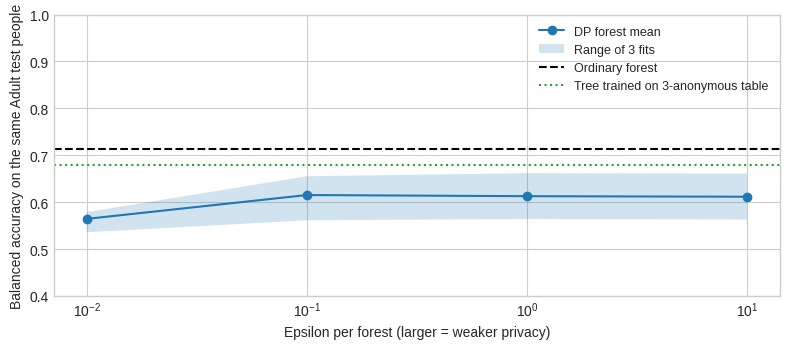

In [17]:
#| echo: false
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(dp_summary.index, dp_summary["mean"], marker="o", label="DP forest mean")
ax.fill_between(dp_summary.index, dp_summary["min"], dp_summary["max"], alpha=0.2, label="Range of 3 fits")
ax.axhline(forest_reference["balanced_accuracy"], color="black", linestyle="--", label="Ordinary forest")
ax.axhline(tree_results.loc[tree_results.target_k.eq(TARGET_K), "balanced_accuracy"].iloc[0], color="C2", linestyle=":", label="Tree trained on 3-anonymous table")
ax.set(xscale="log", ylim=(0.4,1), xlabel="Epsilon per forest (larger = weaker privacy)",
       ylabel="Balanced accuracy on the same Adult test people")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


# Attack-to-defense map

| Attack | Main idea | Better response |
|---|---|---|
| Record linkage | Join quasi-identifiers with outside data | $k$-anonymity, stronger generalization |
| Homogeneity | All group members share a sensitive value | $l$-diversity |
| Skewness | Group income distribution differs from the released population | $t$-closeness |
| Differencing | Compare overlapping query answers | differential privacy, query auditing |
| Membership inference | Detect whether one record was included | differential privacy |


# Final comparison: different guarantees, common utility

Compare predictive utility on the same test people, while stating the guarantee separately:

- The anonymized training table satisfies $k = 3$; its ordinary tree has no DP guarantee.
- DP rows average three seeded simulations at each $\epsilon$.
- $k$ and $\epsilon$ do not share a privacy scale. These methods cannot be ranked on one common privacy axis.


In [18]:
#| echo: false
def final_comparison(tree_table, private_results):
    trees = tree_table.copy()
    anonymous = trees.target_k.notna()
    trees["privacy_claim"] = np.where(anonymous, "Training table k>=3; model not DP", "No DP guarantee")
    trees["input_representation"] = np.where(anonymous, "Generalized five QIs", "Raw five QIs")
    trees["epsilon_per_fit"] = np.nan

    ordinary = pd.DataFrame([{**forest_reference, "retained_share": 1.0,
        "privacy_claim": "No DP guarantee", "input_representation": "Raw five QIs",
        "epsilon_per_fit": np.nan}])

    private = private_results.groupby("epsilon", as_index=False)[
        ["accuracy", "balanced_accuracy", "f1", "test_people"]].mean()
    private["model"] = private.epsilon.map(lambda value: f"DP forest epsilon={value:g}")
    private["privacy_claim"] = "Seeded DP simulation"
    private["input_representation"] = "Raw five QIs"
    private["epsilon_per_fit"] = private.pop("epsilon")
    private["retained_share"] = 1.0
    return pd.concat([trees, ordinary, private], ignore_index=True)

comparison = final_comparison(tree_results, dp_results)
display(comparison[["model", "privacy_claim", "epsilon_per_fit", "retained_share",
                    "accuracy", "balanced_accuracy", "f1"]].rename(columns={
    "model": "Model", "privacy_claim": "Guarantee", "epsilon_per_fit": "Epsilon / fit",
    "retained_share": "Retained", "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced acc.", "f1": "F1"}).round(3))


,Model,Guarantee,Epsilon / fit,Retained,Accuracy,Balanced acc.,F1
0,Raw decision tree,No DP guarantee,NaN,1.000,0.824,0.686,0.533
1,"Anonymized decision tree, k=3",Training table k>=3; model not DP,NaN,0.995,0.822,0.678,0.520
2,Ordinary random forest,No DP guarantee,NaN,1.000,0.826,0.713,0.577
3,DP forest epsilon=0.01,Seeded DP simulation,0.01,1.000,0.772,0.564,0.256
4,DP forest epsilon=0.1,Seeded DP simulation,0.10,1.000,0.802,0.615,0.373
5,DP forest epsilon=1,Seeded DP simulation,1.00,1.000,0.802,0.613,0.367
6,DP forest epsilon=10,Seeded DP simulation,10.00,1.000,0.801,0.612,0.364


# Compare utility on the same test people

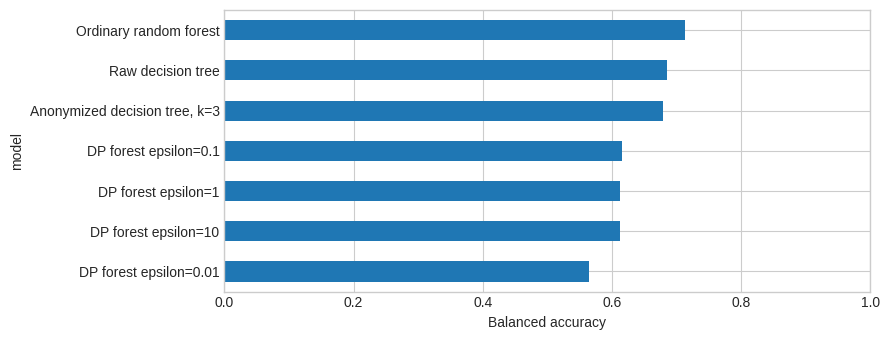

In [19]:
#| echo: false
fig, ax = plt.subplots(figsize=(9, 3.5))
comparison.set_index("model").balanced_accuracy.sort_values(ascending=True).plot.barh(ax=ax)
ax.set(xlim=(0,1),xlabel="Balanced accuracy")
plt.tight_layout()
plt.show()


# Why a high accuracy can still hide a poor income classifier

Treat **income >50K** as the positive class.

- **Precision:** among people predicted to earn >50K, how many actually do? Low precision means many false positives.
- **Recall:** among people who actually earn >50K, how many does the model find? Low recall means many high-income people are missed.

Most Adult records have income <=50K, so high accuracy can coexist with poor recall for >50K.

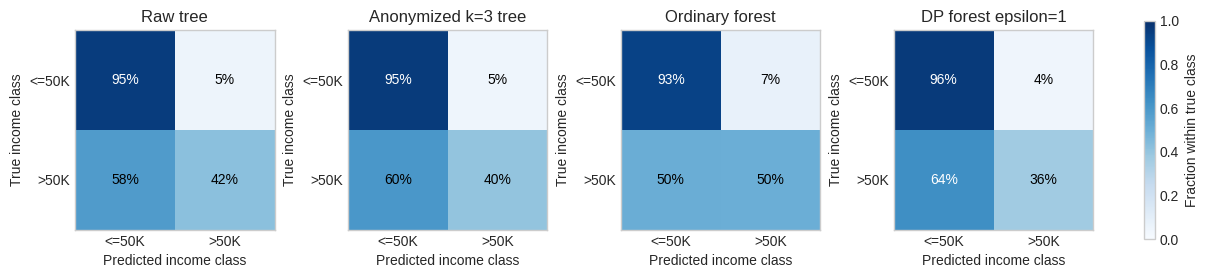

In [20]:
#| echo: false
diagnostics = [("Raw tree",raw_tree,test_df[QI]),("Anonymized k=3 tree",anon_tree,gen_test[GEN_QI]),
               ("Ordinary forest",raw_forest,test_df[QI]),("DP forest epsilon=1",dp_models[(1.,42)],test_df[QI])]
fig, axes = plt.subplots(1,4,figsize=(12,3.2),layout="constrained")
for ax,(title,model,features) in zip(axes,diagnostics):
    matrix = confusion_matrix(y_test,model.predict(features),labels=[0,1],normalize="true")
    im = ax.imshow(matrix,cmap="Blues",vmin=0,vmax=1)
    ax.grid(False)
    for i in range(2):
        for j in range(2): ax.text(j,i,f"{matrix[i,j]:.0%}",ha="center",va="center",color="white" if matrix[i,j]>.6 else "black")
    ax.set(title=title,xlabel="Predicted income class",ylabel="True income class",xticks=[0,1],yticks=[0,1],
           xticklabels=["<=50K", ">50K"], yticklabels=["<=50K", ">50K"])
fig.colorbar(im,ax=axes,shrink=.7,label="Fraction within true class")
plt.show()


{{< include _coding_break3.qmd >}}


# Exercises: guided practice on Adult

| Already provided | Purpose |
| --- | --- |
| `QI`, `GEN_QI`, `df`, `train_df`, `test_df`, `y_train`, `y_test` | Columns, data and fixed split |
| `group_sizes`, `audit_k` | Count groups and check $k$ |
| `make_preprocessor`, `make_tree_pipeline` | Encode inputs and build the fixed tree |
| `evaluate`, `tree_feature_report` | Report metrics and used features |
| `make_forest_pipeline`, `EPSILONS`, `BudgetAccountant` | Fit DP forests and track budgets |
| `final_comparison` | Combine your saved result tables |


# Exercise 1: does raw Adult satisfy $k = 3$?

<a id="coding-exercises-1"></a>

<a id="exercise-1"></a>

Group the original Adult records by the five QIs and check the smallest group.

**Use:** `df`, `QI`, `audit_k`. **Save:** `student_raw_report`.

Does the smallest group reach 3? What fraction of records belong to smaller groups?


In [27]:
# 1. Group df by QI only; income is not part of the key.
# 2. Use audit_k to obtain k_min and share_rows_below_k.
# 3. Display a few groups containing fewer than 3 records.
# 4. Answer using the minimum group size, not the average.

student_sizes = df.groupby(QI, dropna=False).size()  # Hint: QI.
student_raw_report = audit_k(df, QI)  # Hint: df and QI.
display(student_raw_report[["k_min", "share_rows_below_k"]])
display(student_sizes[student_sizes < 3].head())


,0
k_min,1
share_rows_below_k,0.13169


age  education_num  marital_status      race   sex   
17   3              Never-married       White  Female    1
                                               Male      2
     4              Never-married       Other  Male      1
                                        White  Female    1
     5              Married-civ-spouse  White  Male      1
dtype: int64

# Exercise 2: generalize and suppress {.scrollable}

<a id="exercise-2"></a>

Complete two small functions for our single $k = 3$ release:

1. `student_generalize(table)`: put age into 10-year bands, education into four-level bands and marital status into married / not married. Keep race, sex and income unchanged.
2. `student_suppress(table, qi, k=3)`: remove rows in QI groups containing fewer than $k$ records.

**Hints:** `//` is integer division: `(39 // 10) * 10` gives `30`, the label for ages 30–39. Education starts at 1: `((level - 1) // 4) * 4 + 1` labels the bands 1–4, 5–8, 9–12 and 13–16.

How many records remain, and does the release meet $k = 3$?


In [28]:
# 1. Complete student_generalize: copy the table and fill in the two band widths.
# 2. Complete student_suppress: count how many rows share each row's QI values.
#    Hint: groupby(qi)["income"].transform("size") repeats the group size
#    on every original row. Income is counted, not used as a grouping key.
# 3. Keep rows whose group size is at least k; return a copy.
# 4. Apply your function to the generalized Adult table, then check it.

def student_generalize(table):
    out = table.copy()  # Keep the original data and row index unchanged.
    out["age_band"] = (out["age"] // 10) * 10  # Hint: 10-year bands.
    out["education_band"] = ((out["education_num"] - 1) // 4) * 4 + 1  # Hint: groups of 4 education levels.
    out["marital_group"] = np.where(out["marital_status"].str.startswith("Married"), "Married", "Not married")  # Hint: "Not married".
    return out[GEN_QI + ["income"]]  # Keep race, sex and income unchanged.

def student_suppress(table, qi, k=3):
    sizes = table.groupby(qi, dropna=False)["income"].transform("size")  # Hint: qi.
    return table.loc[sizes >= k].copy()  # Hint: k.

student_generalized = student_generalize(df)  # Your function.
student_release = student_suppress(student_generalized, GEN_QI, k=3)
student_release_report = audit_k(student_release, GEN_QI)  # Already provided: audit_k.
display(student_release_report)
assert student_release_report.meets_target
print("Retained share:", len(student_release) / len(df))
display(student_release.reset_index(drop=True).head(2))


,0
records,48663
groups,347
k_min,3
singleton_share,0.0
share_rows_below_k,0.0
meets_target,True


Retained share: 0.9963351214118996


,age_band,education_band,marital_group,race,sex,income
0,30,13,Not married,White,Male,<=50K
1,50,13,Married,White,Male,<=50K


# Coding session 1 solution {.scrollable}

<details>
<summary>Show the solution</summary>

```python
# Exercise 1
student_sizes = df.groupby(QI, dropna=False).size()  # Hint: QI.
student_raw_report = audit_k(df, QI)  # Hint: df and QI.
display(student_raw_report[["k_min", "share_rows_below_k"]])
display(student_sizes[student_sizes < 3].head())

# Exercise 2
def student_generalize(table):
    out = table.copy()  # Keep the original data and row index unchanged.
    out["age_band"] = (out["age"] // 10) * 10
    out["education_band"] = ((out["education_num"] - 1) // 4) * 4 + 1
    out["marital_group"] = np.where(out["marital_status"].str.startswith("Married"), "Married", "Not married")
    return out[GEN_QI + ["income"]]  # Keep race, sex and income unchanged.

def student_suppress(table, qi, k=3):
    sizes = table.groupby(qi, dropna=False)["income"].transform("size")
    return table.loc[sizes >= k].copy()

student_generalized = student_generalize(df)
display(student_generalized.head())
student_release = student_suppress(student_generalized, GEN_QI, k=3)
student_release_report = audit_k(student_release, GEN_QI)
display(student_release_report)
assert student_release_report.meets_target
print("Retained share:", len(student_release) / len(df))
display(student_release.head())
```

Use the full table only for this audit. Exercise 4 rebuilds the release from the existing training split.

</details>


# Exercise 3: a decision-tree pipeline on raw Adult

<a id="coding-exercises-2"></a>

<a id="exercise-3"></a>

Fit the supplied pipeline on the original QIs.

**Use:** `train_df`, `test_df`, `QI`, `y_train`, `y_test`. **Save:** `student_raw_tree`, `student_raw_result`.

What are accuracy, balanced accuracy and F1? Which features actually appear in splits?


In [29]:
# 1. Reuse the existing training/test split and choose QI as input columns.
# 2. Create the supplied preprocessing + depth-5 decision-tree pipeline.
# 3. Fit on training rows and y_train; evaluate all test rows.
# 4. Display only features whose split_count is greater than 0.

student_raw_tree = make_tree_pipeline()  # Provided: preprocessing + fixed depth-5 tree.
student_raw_tree.fit(train_df[QI], y_train)  # Hint: train_df and y_train.
student_raw_result = evaluate(student_raw_tree, test_df[QI], "Raw tree")
display(pd.Series(student_raw_result))
student_used_features = tree_feature_report(student_raw_tree)
display(student_used_features.query("split_count > 0"))


,0
model,Raw tree
accuracy,0.823517
balanced_accuracy,0.685557
f1,0.533044
test_people,14653


,feature,split_count,importance
2,categories__marital_status,3,0.556970
1,numeric__education_num,8,0.371200
0,numeric__age,14,0.064364
4,categories__sex,6,0.007466


# Exercise 4: a decision tree on anonymized Adult {.scrollable}

<a id="exercise-4"></a>

Use the same generalization as Exercise 2 and suppress training groups smaller than 3. Fit the same decision tree, then compare it with the raw tree from Exercise 3.

How do balanced accuracy, F1 and the retained training share change? Keep every original test person in the comparison.


In [32]:
# 1. Generalize both existing splits with your student_generalize from Exercise 2.
# 2. Use your student_suppress to remove TRAINING groups smaller than 3; verify k.
# 3. Fit the supplied tree on retained training rows and their income labels.
# 4. Evaluate all test people; use the supplied table code to compare both trees.

student_gen_train = student_generalize(train_df)
student_gen_test = student_generalize(test_df)
student_kept = student_suppress(student_gen_train, GEN_QI, k=3)  # Hint: 3.
student_audit = audit_k(student_kept, GEN_QI)
assert student_audit.meets_target
student_labels = student_kept.income.eq(">50K").astype(int)
student_tree = make_tree_pipeline(generalized=True)
student_tree.fit(student_kept[GEN_QI], student_labels)  # Hint: student_labels.
student_anon_result = evaluate(student_tree, student_gen_test[GEN_QI], "Anonymized tree, k=3")  # Hint: GEN_QI.

# Supplied: collect the two models for Exercise 6.
student_tree_results = pd.DataFrame([
    {**student_raw_result, "target_k": np.nan,
     "achieved_k": audit_k(train_df, QI).k_min, "training_rows": len(train_df), "retained_share": 1.0},
    {**student_anon_result, "target_k": 3,
     "achieved_k": student_audit.k_min, "training_rows": len(student_kept),
     "retained_share": len(student_kept) / len(train_df)},
])
display(student_tree_results[["model", "achieved_k", "retained_share", "balanced_accuracy", "f1"]].round(3))


,model,achieved_k,retained_share,balanced_accuracy,f1
0,Raw tree,1,1.000,0.686,0.533
1,"Anonymized tree, k=3",3,0.995,0.678,0.520


# Coding session 2 solution {.scrollable}

<details>
<summary>Show the solution</summary>

```python
# Exercise 3
student_raw_tree = make_tree_pipeline()
student_raw_tree.fit(train_df[QI], y_train)  # Hint: train_df and y_train.
student_raw_result = evaluate(student_raw_tree, test_df[QI], "Raw tree")  # Hint: test_df.
display(pd.Series(student_raw_result))
student_used_features = tree_feature_report(student_raw_tree)
display(student_used_features.query("split_count > 0"))

# Exercise 4
student_gen_train = student_generalize(train_df)
student_gen_test = student_generalize(test_df)
student_kept = student_suppress(student_gen_train, GEN_QI, k=3)
student_audit = audit_k(student_kept, GEN_QI)
assert student_audit.meets_target
student_labels = student_kept.income.eq(">50K").astype(int)
student_tree = make_tree_pipeline(generalized=True)
student_tree.fit(student_kept[GEN_QI], student_labels)
student_anon_result = evaluate(student_tree, student_gen_test[GEN_QI], "Anonymized tree, k=3")
display(tree_feature_report(student_tree))

# Supplied: collect the two models for Exercise 6.
student_tree_results = pd.DataFrame([
    {**student_raw_result, "target_k": np.nan,
     "achieved_k": audit_k(train_df, QI).k_min, "training_rows": len(train_df), "retained_share": 1.0},
    {**student_anon_result, "target_k": 3,
     "achieved_k": student_audit.k_min, "training_rows": len(student_kept),
     "retained_share": len(student_kept) / len(train_df)},
])
display(student_tree_results[["model", "achieved_k", "retained_share", "balanced_accuracy", "f1"]].round(3))
```
</details>


# Exercise 5: a DP random forest under different budgets

<a id="coding-exercises-3"></a>

<a id="exercise-5"></a>

Train one private forest at each value in EPSILONS, changing only $\epsilon$. The helper supplies the feature bounds, label domain, tree count and depth.

How do balanced accuracy and F1 change? How much $\epsilon$ does the whole sweep spend?


In [25]:
# 1. Create one accountant BEFORE the loop with budget sum(EPSILONS).
# 2. Use the same accountant for every forest; keep seed 142 fixed for this public-data exercise.
# 3. Fit raw training QIs and evaluate the same raw test QIs.
# 4. Save one row per epsilon, then display metrics and the total spending.

student_accountant = BudgetAccountant(epsilon=sum(EPSILONS) + 1e-8, delta=0)
student_dp_rows = []
for epsilon in EPSILONS:
    student_forest = make_forest_pipeline(
        epsilon=epsilon, seed=142, accountant=student_accountant)  # Hint: epsilon and student_accountant.
    student_forest.fit(train_df[QI], y_train)  # Hint: train_df and y_train.
    student_row = evaluate(student_forest, test_df[QI], f"DP forest epsilon={epsilon:g}")
    student_dp_rows.append({"epsilon": epsilon, **student_row})  # Test input: test_df.
student_dp_table = pd.DataFrame(student_dp_rows)
display(student_dp_table[["epsilon", "balanced_accuracy", "f1"]].round(3))
print("Sweep privacy spending:", student_accountant.total())


# Exercise 6: compare privacy and utility

<a id="exercise-6"></a>

Combine the results already computed. The helper adds the provided ordinary-forest reference.

**Use:** `student_tree_results` from Exercise 4 and `student_dp_table` from Exercise 5.

Which release would you choose for a stated use case? What utility or coverage would you give up?


In [26]:
# 1. Pass your two saved tables to final_comparison; no retraining is needed.
# 2. Display each privacy claim, retained share, balanced accuracy and F1.
# 3. Use the supplied plot template for all models and the DP budget curve.
# 4. Report total epsilon and distinguish table anonymity from model DP.

student_comparison = final_comparison(student_tree_results, student_dp_table)  # Your tree table, then your DP table.
display(student_comparison[["model", "privacy_claim", "retained_share",
    "balanced_accuracy", "f1"]].round(3))
fig, (ax_models, ax_dp) = plt.subplots(1, 2, figsize=(12, 4.5))
student_comparison.set_index("model")["balanced_accuracy"].plot.barh(
    ax=ax_models, xlim=(0, 1), title="Same Adult test people")
student_dp_table.plot(x="epsilon", y="balanced_accuracy", logx=True,
    marker="o", ax=ax_dp, legend=False)
ax_dp.axhline(forest_reference["balanced_accuracy"], color="black",
    linestyle="--", label="Ordinary forest")
ax_dp.set(xlabel="Epsilon per fit", ylabel="Balanced accuracy", ylim=(0.4, 1))
ax_dp.legend()
plt.tight_layout()
plt.show()
print("Student sweep epsilon:", student_accountant.total()[0])
print("Main demonstration + student sweep epsilon:",
    forest_accountant.total()[0] + student_accountant.total()[0])


# Coding session 3 solution {.scrollable}

<details>
<summary>Show the solution</summary>

```python
# Exercise 5
# Fixed seeds reproduce the public-data exercise, not a confidential DP release.
student_accountant = BudgetAccountant(epsilon=sum(EPSILONS) + 1e-8, delta=0)
student_dp_rows = []
for epsilon in EPSILONS:
    student_forest = make_forest_pipeline(
        epsilon=epsilon, seed=142, accountant=student_accountant)  # Hint: epsilon and student_accountant.
    student_forest.fit(train_df[QI], y_train)  # Hint: train_df and y_train.
    student_row = evaluate(student_forest, test_df[QI], f"DP forest epsilon={epsilon:g}")
    student_dp_rows.append({"epsilon": epsilon, **student_row})  # Test input: test_df.
student_dp_table = pd.DataFrame(student_dp_rows)
display(student_dp_table[["epsilon", "balanced_accuracy", "f1"]].round(3))
print("Sweep privacy spending:", student_accountant.total())

# Exercise 6
student_comparison = final_comparison(student_tree_results, student_dp_table)  # Your tree table, then your DP table.
display(student_comparison[["model", "privacy_claim", "retained_share",
    "balanced_accuracy", "f1"]].round(3))
fig, (ax_models, ax_dp) = plt.subplots(1, 2, figsize=(12, 4.5))
student_comparison.set_index("model")["balanced_accuracy"].plot.barh(
    ax=ax_models, xlim=(0, 1), title="Same Adult test people")
student_dp_table.plot(x="epsilon", y="balanced_accuracy", logx=True,
    marker="o", ax=ax_dp, legend=False)
ax_dp.axhline(forest_reference["balanced_accuracy"], color="black",
    linestyle="--", label="Ordinary forest")
ax_dp.set(xlabel="Epsilon per fit", ylabel="Balanced accuracy", ylim=(0.4, 1))
ax_dp.legend()
plt.tight_layout()
plt.show()
print("Student sweep epsilon:", student_accountant.total()[0])
print("Main demonstration + student sweep epsilon:",
    forest_accountant.total()[0] + student_accountant.total()[0])
```
</details>


# Further reading

- [diffprivlib random forest](https://diffprivlib.readthedocs.io/en/latest/modules/models.html#tree-based-models).
- [PermuteAndFlip](https://diffprivlib.readthedocs.io/en/latest/modules/mechanisms.html#diffprivlib.mechanisms.PermuteAndFlip).
- [BudgetAccountant](https://diffprivlib.readthedocs.io/en/latest/modules/accountant.html).


# References

::: {#refs}
:::
